# BDB 2027 — Get-off as a health vital sign

The last notebook found one movement mechanic that tracked injury-like absences: **get-off**, the time from the snap until a player has moved half a yard. It slowed before long absences and recovered after them. But with 11 long-absence events among OL, it couldn't be tested as a predictor.

This notebook takes the three steps that fix that:

1. **Real injury labels.** Public weekly NFL injury reports (nflverse) are joined to the BDB data. They give practice participation, game status and body part, and BDB `nfl_id`s map directly to nflverse `gsis_id`s.
2. **All positions pooled.** The personal-baseline method works for anyone, so the whole cohort (OL, DL, DB, WR, TE) is used, with OL kept as a subgroup throughout.
3. **Movement degradation as a continuous outcome.** Instead of only predicting rare events, the notebook models get-off itself, game by game, with mixed-effects models: what makes it slow down, and how much slower is a player when he's on the injury report?

Then it ties get-off back to the Combine:
- Does Combine burst carry into NFL get-off?
- Does Combine capacity change how much load or injury slows a player?
- Who wears down over a season, and does the Combine see it coming?

| § | What |
|---|---|
| 1–2 | BDB tables, position groups, injury-report join, and a **proxy audit**: how often were "absences" actually injuries? |
| 3 | Player-game panel for the whole cohort, with injury status per game |
| 4 | Rep mechanics from all game tracking (chunked, cached): get-off, burst, speed, accel/decel |
| 5 | **Vital-sign tests**: get-off while listed vs. healthy; event-aligned get-off around injury onset; return curves |
| 6 | **Degradation models** (mixed effects): season wear, load → next-game get-off, injury-status effects |
| 7 | **Combine tie-in**: Combine burst ↔ NFL get-off, capacity × load and capacity × injury moderation, wear slopes, recovery |
| 8 | Onset prediction with real labels (grouped CV), all positions and OL |
| 9 | Synthesis |

Requires `statsmodels` (`pip install statsmodels`) for the mixed models.

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="An input array is constant")

pd.set_option("display.max_columns", 120); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

CANDIDATES = [Path("data"), Path("../data"), Path("data/raw"), Path("/kaggle/input/nfl-big-data-bowl-2027")]
DATA_DIR = next((p for p in CANDIDATES if (p / "games.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("games.csv not found in: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
print("Data dir:", DATA_DIR.resolve())
EXT_DIR = Path("external"); EXT_DIR.mkdir(exist_ok=True)   # nflverse downloads are cached here
NULLS = ["NA", "NULL", "null", "None", ""]

def find_csv(stem):
    f = DATA_DIR / f"{stem}.csv"
    if not f.exists(): raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return f

def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None

# ---- knobs ---------------------------------------------------------------
SEASONS        = [2023, 2024, 2025]
REGULAR_SNAPS  = 20     # ≥ this many snaps = established (pooled positions, so lower than the OL-only 30)
EXIT_FRAC      = 0.5
LONG_ABSENCE   = 4
REP_WINDOW_S   = 3.0
MIN_REPS_GAME  = 8
BASE_K, BASE_MIN = 6, 3
PRE, POST      = 5, 8     # event window around injury onset (played games)
HI_DECEL       = 3.0
N_BOOT         = 1000
RNG            = np.random.default_rng(27)
REP_CACHE      = Path("cohort_rep_mechanics.parquet")
NFLVERSE       = "https://github.com/nflverse/nflverse-data/releases/download"
SNAP           = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
# --------------------------------------------------------------------------

def cluster_boot_mean(values, clusters, n=N_BOOT):
    d = pd.DataFrame({"v": values, "c": clusters}).dropna()
    if d.empty: return np.nan, np.nan, np.nan, 0
    agg = d.groupby("c")["v"].agg(["sum", "size"]); k = len(agg)
    if k < 3: return d["v"].mean(), np.nan, np.nan, len(d)
    draws = RNG.integers(0, k, (n, k)); s, c = agg["sum"].to_numpy(), agg["size"].to_numpy()
    return d["v"].mean(), *np.percentile(s[draws].sum(1) / c[draws].sum(1), [2.5, 97.5]), len(d)

def cluster_boot_auc(y, p, clusters, n=500):
    d = pd.DataFrame({"y": y, "p": p, "c": clusters}).dropna()
    a = roc_auc_score(d["y"], d["p"]) if d["y"].nunique() == 2 else np.nan
    groups = [g for _, g in d.groupby("c")]; k = len(groups); bs = []
    for _ in range(n):
        s = pd.concat([groups[i] for i in RNG.integers(0, k, k)])
        if s["y"].nunique() == 2: bs.append(roc_auc_score(s["y"], s["p"]))
    return a, *(np.percentile(bs, [2.5, 97.5]) if bs else (np.nan, np.nan))

def poisson_rate(e, x, per=100):
    lo = stats.chi2.ppf(.025, 2 * e) / 2 if e > 0 else 0.0
    hi = stats.chi2.ppf(.975, 2 * (e + 1)) / 2
    return per * e / x, per * lo / x, per * hi / x

Data dir: C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


## 1. BDB tables and position groups

In [2]:
players = pd.read_csv(find_csv("players"), na_values=NULLS)
combine = pd.read_csv(find_csv("combine_results"), na_values=NULLS)
games   = pd.read_csv(find_csv("games"), na_values=NULLS)
pp      = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

prof = players.merge(combine.drop(columns=[c for c in combine if c in players and c != "nfl_id"]), on="nfl_id", how="left")
NAME = pick(prof, ["display_name", "player_name", "full_name", "name"])
NFL_POS, CMB_POS = pick(prof, ["nfl_position", "position"]), pick(prof, ["combine_position"])
DRAFT_YR = pick(prof, ["draft_year"], required=True)
PICK = pick(prof, ["draft_pick", "draft_overall_pick", "overall_pick", "draft_number"])
TEAM = pick(pp, ["team_abbr", "club", "team"], required=True)
DIR, QTR = pick(pp, ["play_direction"]), pick(pp, ["quarter"])
HOME, AWAY = pick(games, ["home_team_abbr"]), pick(games, ["visitor_team_abbr", "away_team_abbr"])
GDATE = pick(games, ["game_date", "date", "gameday"])

POS_MAP = {**{p: "OL" for p in ["T", "G", "C", "OT", "OG", "OL", "IOL", "LT", "RT", "LG", "RG"]},
           **{p: "DL" for p in ["DT", "NT", "DE", "DL", "IDL"]},
           **{p: "EDGE" for p in ["OLB", "EDGE", "ED"]},
           **{p: "LB" for p in ["LB", "ILB", "MLB"]},
           **{p: "DB" for p in ["CB", "S", "FS", "SS", "DB", "SAF"]},
           "WR": "WR", "TE": "TE", "RB": "RB", "FB": "RB", "QB": "QB"}
src = prof[NFL_POS] if NFL_POS else prof[CMB_POS]
prof["pos_group"] = src.astype(str).str.upper().map(POS_MAP)
if CMB_POS: prof["pos_group"] = prof["pos_group"].fillna(prof[CMB_POS].astype(str).str.upper().map(POS_MAP))
prof["pos_group"] = prof["pos_group"].fillna("other")
print(prof["pos_group"].value_counts().to_dict())

{'OL': 121, 'DB': 118, 'WR': 106, 'DL': 88, 'TE': 42, 'EDGE': 30, 'LB': 3, 'RB': 2}


## 2. Public injury reports (nflverse) and the proxy audit

The reports and the nflverse player table are downloaded once and cached in `external/`. The player table carries `nfl_id`, which matches BDB's `nfl_id`, so the join is by ID rather than by name.

**Per player-week we keep:** whether he was listed, his game status (Out / Doubtful / Questionable), his practice status (DNP / Limited / Full), and the primary body part, grouped into regions. Reasons marked "not injury related," rest, illness and personal are excluded from injury events.

**Injury onset** = listed with a real injury this week, after **not** being listed with an injury the previous team week.

In [3]:
def nflverse_csv(tag, fname):
    local = EXT_DIR / fname
    if not local.exists():
        url = f"{NFLVERSE}/{tag}/{fname}"
        print("downloading", url)
        pd.read_csv(url, low_memory=False).to_csv(local, index=False)
    return pd.read_csv(local, low_memory=False)

nv_players = nflverse_csv("players", "players.csv")
idmap = nv_players.dropna(subset=["nfl_id"])[["gsis_id", "nfl_id"]].astype({"nfl_id": "int64"}).drop_duplicates("gsis_id")
inj = pd.concat([nflverse_csv("injuries", f"injuries_{y}.csv") for y in SEASONS], ignore_index=True)
inj = inj[inj["game_type"] == "REG"].copy()
if "date_modified" in inj: inj = inj.sort_values("date_modified")
inj = inj.drop_duplicates(["season", "week", "gsis_id"], keep="last").merge(idmap, on="gsis_id", how="inner")
inj = inj[inj["nfl_id"].isin(prof["nfl_id"])]

REGIONS = {"lower": ["knee", "ankle", "foot", "hamstring", "calf", "hip", "groin", "achilles", "quad", "toe",
                     "thigh", "shin", "leg", "heel", "fibula", "tibia", "mcl", "acl"],
           "upper": ["shoulder", "elbow", "wrist", "hand", "finger", "thumb", "arm", "pector", "bicep", "tricep",
                     "chest", "rib", "forearm", "clavicle"],
           "trunk": ["back", "abdomen", "oblique", "neck", "core", "spine"],
           "head": ["concussion", "head", "eye", "jaw", "face"]}
NON_INJ = ["not injury", "rest", "illness", "personal", "coach", "nir"]
def region(s):
    s = str(s).lower()
    if s in ("nan", "") or any(k in s for k in NON_INJ): return "non-injury"
    for r, keys in REGIONS.items():
        if any(k in s for k in keys): return r
    return "other"
body = inj["report_primary_injury"].fillna(inj.get("practice_primary_injury"))
inj["region"] = body.map(region)
inj["is_injury"] = inj["region"] != "non-injury"
inj["status"] = inj["report_status"].fillna("listed (no game status)")
inj["practice"] = inj["practice_status"].fillna("")
inj["limited"] = inj["practice"].str.contains("Limited|Did Not", case=False) | inj["status"].isin(["Questionable", "Doubtful"])
weekly = inj[["nfl_id", "season", "week", "is_injury", "region", "status", "practice", "limited"]]
print(f"injury-report rows for cohort players: {len(weekly):,} | players listed at least once: {weekly['nfl_id'].nunique()}")
display(weekly.groupby(["region"]).size().to_frame("player-weeks"))

downloading https://github.com/nflverse/nflverse-data/releases/download/players/players.csv
downloading https://github.com/nflverse/nflverse-data/releases/download/injuries/injuries_2023.csv
downloading https://github.com/nflverse/nflverse-data/releases/download/injuries/injuries_2024.csv
downloading https://github.com/nflverse/nflverse-data/releases/download/injuries/injuries_2025.csv
injury-report rows for cohort players: 1,718 | players listed at least once: 321


,player-weeks
region,
head,115
lower,1056
non-injury,129
other,8
trunk,119
upper,291


## 3. Player-game panel (all positions) with injury status

In [4]:
gcols = ["game_id", "season", "week"] + [c for c in ["season_type"] if c in games]
cp = pp.merge(games[gcols], on="game_id", how="left")
if "season_type" in cp: cp = cp[cp["season_type"].fillna("REG") == "REG"]

sched = pd.concat([games[["game_id", "season", "week", HOME]].rename(columns={HOME: "team"}),
                   games[["game_id", "season", "week", AWAY]].rename(columns={AWAY: "team"})])
if "season_type" in games: sched = sched[sched["game_id"].isin(games.loc[games["season_type"] == "REG", "game_id"])]
if GDATE: sched = sched.merge(games[["game_id", GDATE]], on="game_id")
sched = sched.sort_values(["team", "season", "week"])
sched["team_game_no"] = sched.groupby(["team", "season"]).cumcount() + 1
sched["rest_days"] = sched.groupby(["team", "season"])[GDATE].transform(lambda s: pd.to_datetime(s).diff().dt.days) if GDATE else np.nan

pg = cp.groupby(["nfl_id", "game_id", "season", "week"]).agg(snaps=("play_id", "size"), team=(TEAM, "first")).reset_index()
stint = (pg.merge(sched[["game_id", "team", "team_game_no"]], on=["game_id", "team"])
           .groupby(["nfl_id", "season", "team"])["team_game_no"].agg(first_g="min", last_g="max").reset_index())
stint["multi"] = stint.groupby(["nfl_id", "season"])["team"].transform("nunique") > 1
panel = stint.merge(sched, on=["season", "team"])
panel = panel[(panel["team_game_no"] >= panel["first_g"]) & ((panel["team_game_no"] <= panel["last_g"]) | ~panel["multi"])]
panel = panel.merge(pg[["nfl_id", "game_id", "snaps"]], on=["nfl_id", "game_id"], how="left").fillna({"snaps": 0})
panel = panel.merge(weekly, on=["nfl_id", "season", "week"], how="left")
panel["is_injury"] = panel["is_injury"].fillna(False).astype(bool)
panel["limited"] = panel["limited"].fillna(False).astype(bool)
panel = panel.merge(prof[["nfl_id", "pos_group", DRAFT_YR]], on="nfl_id", how="left")
panel["season_of_career"] = panel["season"] - panel[DRAFT_YR] + 1
panel = panel.sort_values(["nfl_id", "season", "team", "team_game_no"]).reset_index(drop=True)

G = panel.groupby(["nfl_id", "season", "team"])
panel["played"] = panel["snaps"] > 0
panel["established"] = G["snaps"].transform(lambda s: (s >= REGULAR_SNAPS).shift(fill_value=False).cummax())
panel["prev_played"] = G["played"].shift(fill_value=False)
panel["trail_med"] = G["snaps"].transform(lambda s: s.where(s >= REGULAR_SNAPS).shift().expanding().median())
panel["absence_start"] = panel["established"] & panel["prev_played"] & ~panel["played"]
panel["spell_id"] = (panel["played"] != G["played"].shift()).cumsum()
panel["spell_len"] = panel["spell_id"].map(panel[~panel["played"]].groupby("spell_id").size()).where(panel["absence_start"])
panel["long_absence_start"] = panel["absence_start"] & (panel["spell_len"] >= LONG_ABSENCE)
panel["exit"] = panel["established"] & panel["played"] & panel["trail_med"].notna() & (panel["snaps"] < EXIT_FRAC * panel["trail_med"])
panel["onset"] = panel["is_injury"] & ~G["is_injury"].shift(fill_value=False)
panel["onset_region"] = panel["region"].where(panel["onset"])
for c in ["onset", "absence_start", "long_absence_start"]:
    panel[f"next_{c}"] = G[c].shift(-1, fill_value=False)
panel["next_onset_lower"] = G["onset_region"].shift(-1).eq("lower")
panel["status_cat"] = np.select(
    [~panel["is_injury"], panel["is_injury"] & panel["limited"]],
    ["healthy", "listed: limited/Q"], "listed: full/no status")
print(f"panel {len(panel):,} player-team-games | players {panel['nfl_id'].nunique()} | "
      f"injury onsets {int(panel['onset'].sum())} (lower body {int((panel['onset_region'] == 'lower').sum())})")

C:\Users\bchm5\AppData\Local\Temp\ipykernel_28024\3931611496.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  panel["is_injury"] = panel["is_injury"].fillna(False).astype(bool)
C:\Users\bchm5\AppData\Local\Temp\ipykernel_28024\3931611496.py:22: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  panel["limited"] = panel["limited"].fillna(False).astype(bool)


panel 10,526 player-team-games | players 401 | injury onsets 740 (lower body 461)


In [5]:
# Proxy audit: were last notebook's 'absences' injuries?
a = panel[panel["absence_start"]].copy()
a["listed_that_week"] = a["is_injury"]
a["listed_prev_week"] = G["is_injury"].shift().reindex(a.index).fillna(False)
a["injury_explains"] = a["listed_that_week"] | a["listed_prev_week"]
a["kind"] = np.where(a["long_absence_start"], f"long ({LONG_ABSENCE}+)", np.where(a["spell_len"] == 1, "1 game", "2–3 games"))
audit = a.groupby("kind").agg(absences=("nfl_id", "size"), share_injury_listed=("injury_explains", "mean")).round(2)
audit.loc["all"] = [len(a), a["injury_explains"].mean().round(2)]
display(audit)
ex = panel[panel["exit"]]
print(f"In-game exits followed by an injury listing that week or the next: "
      f"{(G['is_injury'].shift(-1).reindex(ex.index).fillna(False) | ex['is_injury']).mean():.0%} of {len(ex)}")

C:\Users\bchm5\AppData\Local\Temp\ipykernel_28024\2634220186.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  a["listed_prev_week"] = G["is_injury"].shift().reindex(a.index).fillna(False)


,absences,share_injury_listed
kind,,
1 game,220.0,0.54
2–3 games,151.0,0.52
long (4+),118.0,0.47
all,489.0,0.52


In-game exits followed by an injury listing that week or the next: 20% of 857


C:\Users\bchm5\AppData\Local\Temp\ipykernel_28024\2634220186.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  f"{(G['is_injury'].shift(-1).reindex(ex.index).fillna(False) | ex['is_injury']).mean():.0%} of {len(ex)}")


## 4. Rep mechanics for the whole cohort (chunked + cached)

The season files are too large to hold in memory, so each chunk is reduced to **one row per rep** (player × play), and only that table is kept. Chunks are cut at `game_id` boundaries (the file is assumed to be grouped by game), and any rep split across chunks is caught and dropped. The first run takes a while. Later runs load `cohort_rep_mechanics.parquet` instantly.

**Mechanics** (first `REP_WINDOW_S` s after the snap):
- `get_off`: time to 0.5 yd of displacement
- `burst`: time from first movement (0.5 yd) to 1.5 yd. This isolates acceleration from reaction, and it's the piece that's comparable to the Combine (§7).
- `peak_speed`, `peak_accel`, `peak_decel`, `dist`

In [6]:
ctx = cp[["game_id", "play_id", "nfl_id"] + [c for c in [DIR, QTR] if c]].drop_duplicates(["game_id", "play_id", "nfl_id"])

def rep_features(f):
    k = ["game_id", "play_id", "nfl_id"]
    f = f.sort_values(k + ["time"])
    snap = f.loc[f["event"].isin(SNAP)].groupby(k)["time"].min().rename("snap_time")
    f = f.merge(snap, left_on=k, right_index=True)
    f["t"] = (f["time"] - f["snap_time"]).dt.total_seconds()
    f = f[(f["t"] >= 0) & (f["t"] <= REP_WINDOW_S)]
    if f.empty: return pd.DataFrame()
    g = f.groupby(k)
    f["disp"] = np.hypot(f["x"] - g["x"].transform("first"), f["y"] - g["y"].transform("first"))
    dt = g["t"].diff()
    f["step"] = np.hypot(g["x"].diff(), g["y"].diff()).fillna(0)
    f["dv"] = (g["s"].diff() / dt).where(dt <= 0.25)
    keys = [f[c] for c in k]
    t_half = f["t"].where(f["disp"] >= 0.5).groupby(keys).min()
    t_15 = f["t"].where(f["disp"] >= 1.5).groupby(keys).min()
    out = pd.DataFrame({
        "get_off": t_half, "t_15yd": t_15, "burst": t_15 - t_half,
        "peak_speed": g["s"].max(), "dist": f.groupby(keys)["step"].sum(),
        "peak_accel": f["dv"].where(f["t"] <= 1.5).groupby(keys).max(),
        "peak_decel": (-f["dv"]).groupby(keys).max(), "n_frames": g.size()})
    return out[out["n_frames"] >= 10].reset_index()

if REP_CACHE.exists():
    rep = pd.read_parquet(REP_CACHE); print("loaded", REP_CACHE)
else:
    parts = []
    use = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "event"]
    for season in SEASONS:
        carry = None
        for ch in pd.read_csv(find_csv(f"game_tracking_{season}"), usecols=use, chunksize=2_000_000, na_values=NULLS):
            ch["time"] = pd.to_datetime(ch["time"], errors="coerce")
            ch = ch.dropna(subset=["nfl_id"])
            if carry is not None: ch = pd.concat([carry, ch], ignore_index=True)
            last = ch["game_id"].iloc[-1]
            carry = ch[ch["game_id"] == last]; ch = ch[ch["game_id"] != last]
            if len(ch): parts.append(rep_features(ch))
        if carry is not None and len(carry): parts.append(rep_features(carry))
        print(season, "processed")
    rep = pd.concat(parts, ignore_index=True)
    dup = rep.duplicated(["game_id", "play_id", "nfl_id"], keep=False)
    if dup.any(): print(f"dropping {dup.sum()} reps split across chunks (file not fully grouped by game)")
    rep = rep[~dup]
    rep.to_parquet(REP_CACHE, index=False)

rep = rep.merge(ctx, on=["game_id", "play_id", "nfl_id"], how="left").merge(prof[["nfl_id", "pos_group"]], on="nfl_id", how="left")
rep["rep_no"] = rep.sort_values("play_id").groupby(["game_id", "nfl_id"]).cumcount()
MECH = ["get_off", "burst", "peak_speed", "peak_accel", "peak_decel", "dist"]
print(f"reps: {len(rep):,} | players: {rep['nfl_id'].nunique()}")
display(rep.groupby("pos_group")[MECH].median().round(3))

2023 processed
2024 processed
2025 processed
reps: 314,902 | players: 497


,get_off,burst,peak_speed,peak_accel,peak_decel,dist
pos_group,,,,,,
DB,0.8,0.5,4.810,3.6,1.9,7.813
DL,0.6,0.4,3.320,3.8,2.3,6.570
EDGE,0.6,0.4,4.220,4.5,2.9,7.828
LB,0.7,0.5,4.060,3.8,2.8,6.803
OL,0.6,0.5,2.780,3.1,2.0,5.581
RB,0.7,0.4,5.515,5.3,2.8,10.346
TE,0.6,0.4,6.030,4.9,1.8,11.317
WR,0.6,0.3,7.060,5.9,1.7,14.022


In [7]:
# Game-level aggregation + personal baselines (z) + raw deviation from baseline (ms) for the degradation models
gl = rep.groupby(["game_id", "nfl_id"]).agg(trk_reps=("play_id", "size"),
                                            hard_decels=("peak_decel", lambda s: (s >= HI_DECEL).sum()),
                                            **{m: (m, "median") for m in MECH}).reset_index()
gl = gl[gl["trk_reps"] >= MIN_REPS_GAME]
panel = panel.drop(columns=[c for c in gl if c in panel and c not in ["game_id", "nfl_id"]]).merge(gl, on=["game_id", "nfl_id"], how="left")
panel = panel.sort_values(["nfl_id", "season", "team_game_no"]).reset_index(drop=True)
trk = panel["trk_reps"].notna()
for m in MECH + ["trk_reps", "hard_decels"]:
    v = panel[m].where(trk); gp = v.groupby(panel["nfl_id"])
    mu = gp.transform(lambda s: s.shift().rolling(BASE_K, min_periods=BASE_MIN).mean())
    sd = gp.transform(lambda s: s.shift().rolling(BASE_K, min_periods=BASE_MIN).std())
    panel[f"base_{m}"] = mu
    panel[f"dev_{m}"] = v - mu
    panel[f"z_{m}"] = (v - mu) / np.maximum(sd, gp.transform("std") * 0.25)
G = panel.groupby(["nfl_id", "season", "team"])
for m in ["get_off", "burst"]:
    panel[f"next_dev_{m}"] = G[f"dev_{m}"].shift(-1)
ch = panel["hard_decels"].where(trk).groupby(panel["nfl_id"]).transform(lambda s: s.shift().rolling(4, min_periods=3).mean())
panel["acwr_decel"] = panel["hard_decels"] / ch
panel["spike"] = (panel["acwr_decel"] > 1.3).astype(float).where(panel["acwr_decel"].notna())
panel["low_load"] = (panel["z_trk_reps"] < -1).astype(float).where(panel["z_trk_reps"].notna())
panel["cum_snaps"] = G["snaps"].cumsum()
print(f"played games with tracking: {trk[panel['played']].mean():.0%} | with baseline: {panel['z_get_off'].notna().sum():,}")

played games with tracking: 82% | with baseline: 5,013


## 5. Is get-off a health vital sign?

Three tests, each using real injury labels:
- **(a) Playing hurt.** In games he *played* while listed (limited practice or Questionable), is his get-off slower than his own healthy baseline? This is broken out by body region and position. Lower-body injuries should show the biggest effect if get-off reflects health.
- **(b) Around injury onset.** Personal get-off z is aligned on the week an injury first appears, from 5 played games before through 8 after. Lag −1 is the game in which the injury most likely happened.
- **(c) Recovery.** After onset, how many games until get-off is back within ±0.5 SD of his pre-injury baseline?

games     hi    lo  Δ get-off vs own baseline (ms)
group status                 region                                                     
OL    healthy                any     1011.0    4.0  -3.2                             0.1
      listed: full/no status any       90.0    9.0 -20.0                            -3.5
                             head       4.0   58.7  20.0                            33.7
                             lower     57.0    2.5 -32.3                           -12.0
                             trunk      6.0   37.2 -43.1                            -3.6
                             upper     23.0   31.0  -9.9                            11.0
      listed: limited/Q      any       39.0    9.4 -28.6                            -9.6
                             head       1.0    NaN   NaN                           -41.7
                             lower     24.0    6.0 -49.7                           -22.4
                             trunk      6.0  113.9 -18.0                            59.4
                             upper      7.0    9.3 -41.7                           -14.3
all   healthy                any     4426.0    1.3  -2.6                            -0.8
      listed: full/no status any      380.0    9.5 -10.0                             0.2
                             head      25.0   38.7 -19.9                            10.6
                             lower    223.0    5.4 -17.6                            -6.2
                             trunk     24.0   45.8  -9.3                            17.2
                             upper    107.0   24.4 -11.1                             6.6
      listed: limited/Q      any      207.0   10.5 -17.1                            -3.7
                             head       8.0   24.8 -77.5                           -30.2
                             lower    141.0   16.2 -16.4                            -1.3
                             trunk     25.0   71.5 -21.1                            25.0
                             upper     32.0   20.4 -87.4                           -28.6

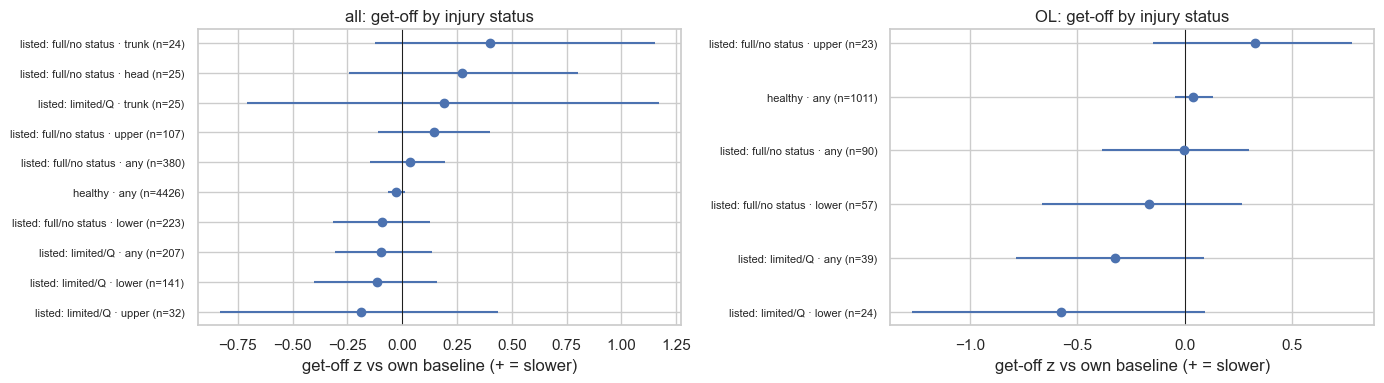

In [8]:
pl = panel[panel["played"] & panel["z_get_off"].notna()].copy()
rows = []
for grp_name, sub in [("all", pl), ("OL", pl[pl["pos_group"] == "OL"])]:
    for cat in ["healthy", "listed: full/no status", "listed: limited/Q"]:
        for reg in (["any"] + list(REGIONS) if cat != "healthy" else ["any"]):
            d = sub[(sub["status_cat"] == cat) & ((sub["region"] == reg) if reg != "any" else True)]
            for m in ["z_get_off", "z_burst", "dev_get_off"]:
                mean, lo, hi, n = cluster_boot_mean(d[m], d["nfl_id"])
                rows.append({"group": grp_name, "status": cat, "region": reg, "metric": m, "mean": mean, "lo": lo, "hi": hi, "games": n})
vs = pd.DataFrame(rows)
show = vs[(vs["metric"] == "dev_get_off")].copy()
show[["mean", "lo", "hi"]] *= 1000   # seconds → ms
display(show.pivot_table(index=["group", "status", "region"], values=["mean", "lo", "hi", "games"]).round(1)
          .rename(columns={"mean": "Δ get-off vs own baseline (ms)"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, gname in zip(axes, ["all", "OL"]):
    d = vs[(vs["group"] == gname) & (vs["metric"] == "z_get_off") & (vs["games"] >= 10)].copy()
    d["label"] = d["status"] + " · " + d["region"]
    d = d.sort_values("mean")
    ax.errorbar(d["mean"], range(len(d)), xerr=[d["mean"] - d["lo"], d["hi"] - d["mean"]], fmt="o")
    ax.set_yticks(range(len(d))); ax.set_yticklabels([f"{l} (n={n})" for l, n in zip(d["label"], d["games"])], fontsize=8)
    ax.axvline(0, color="k", lw=.7); ax.set_xlabel("get-off z vs own baseline (+ = slower)"); ax.set_title(f"{gname}: get-off by injury status")
plt.tight_layout(); plt.show()

onsets with a usable window: 355


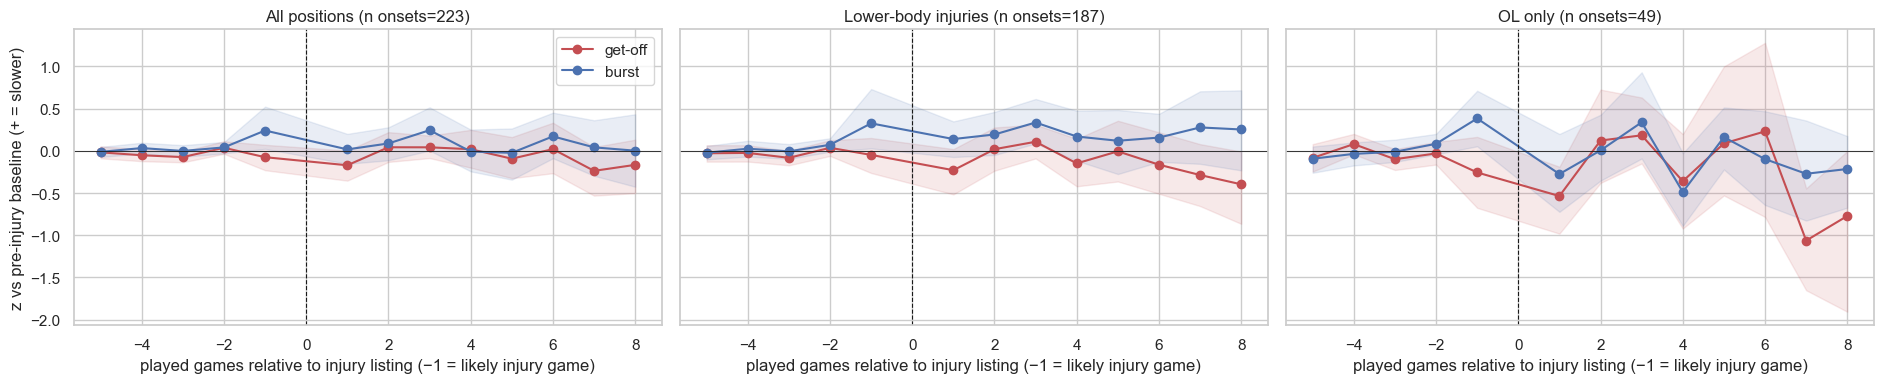

In [9]:
# (b) Event-aligned get-off around injury onset
pt = panel[panel["played"] & panel["trk_reps"].notna()].copy()
pt["pidx"] = pt.groupby("nfl_id").cumcount()
onsets = panel[panel["onset"]][["nfl_id", "season", "team_game_no", "onset_region"]]
# baseline from games BEFORE onset only (so post-onset values are compared to pre-injury self)
rows = []
for _, o in onsets.iterrows():
    mine = pt[pt["nfl_id"] == o["nfl_id"]]
    before = mine[(mine["season"] < o["season"]) | ((mine["season"] == o["season"]) & (mine["team_game_no"] < o["team_game_no"]))]
    after = mine[(mine["season"] == o["season"]) & (mine["team_game_no"] >= o["team_game_no"])]
    if len(before) < BASE_MIN + 1: continue
    base = before.iloc[:-1].tail(BASE_K)            # exclude the likely injury game from the baseline
    mu, sd = base[["get_off", "burst"]].mean(), base[["get_off", "burst"]].std().clip(lower=0.01)   # ≥10 ms floor
    win = pd.concat([before.tail(PRE).assign(rel=np.arange(-min(PRE, len(before)), 0)),
                     after.head(POST).assign(rel=np.arange(1, min(POST, len(after)) + 1))])
    for _, r in win.iterrows():
        rows.append({"nfl_id": o["nfl_id"], "region": o["onset_region"], "pos_group": r["pos_group"], "rel": r["rel"],
                     "z_go": (r["get_off"] - mu["get_off"]) / sd["get_off"], "z_burst": (r["burst"] - mu["burst"]) / sd["burst"]})
ev = pd.DataFrame(rows)
print(f"onsets with a usable window: {ev.groupby(['nfl_id','region']).ngroups if len(ev) else 0}")

if len(ev):
    fig, axes = plt.subplots(1, 3, figsize=(19, 4), sharey=True)
    for ax, (title, sel) in zip(axes, [("All positions", ev), ("Lower-body injuries", ev[ev["region"] == "lower"]),
                                        ("OL only", ev[ev["pos_group"] == "OL"])]):
        for m, col in [("z_go", "#C44E52"), ("z_burst", "#4C72B0")]:
            pts = [(r, *cluster_boot_mean(d[m], d["nfl_id"])) for r, d in sel.groupby("rel")]
            if not pts: continue
            r, mm, lo, hi, n = map(np.array, zip(*pts))
            ax.plot(r, mm, "o-", color=col, label=m.replace("z_go", "get-off").replace("z_burst", "burst"))
            ax.fill_between(r, lo, hi, color=col, alpha=.12)
        ax.axvline(0, color="k", ls="--", lw=.8); ax.axhline(0, color="k", lw=.6)
        ax.set_title(f"{title} (n onsets={sel.groupby(['nfl_id']).ngroups})"); ax.set_xlabel("played games relative to injury listing (−1 = likely injury game)")
    axes[0].set_ylabel("z vs pre-injury baseline (+ = slower)"); axes[0].legend(); plt.tight_layout(); plt.show()

In [10]:
# (c) Recovery: games after onset until get-off is back within ±0.5 SD of pre-injury baseline (3-game rolling)
rec = []
if len(ev):
    for (nid, reg), d in ev[ev["rel"] > 0].groupby(["nfl_id", "region"]):
        d = d.sort_values("rel"); roll = d["z_go"].rolling(2, min_periods=1).mean()
        back = d.loc[roll.abs() <= 0.5, "rel"]
        rec.append({"nfl_id": nid, "region": reg, "games_to_baseline": back.iloc[0] if len(back) else np.nan,
                    "recovered_in_window": len(back) > 0, "first3_z": d.head(3)["z_go"].mean()})
rec = pd.DataFrame(rec)
if len(rec):
    display(rec.groupby("region").agg(onsets=("nfl_id", "size"), recovered=("recovered_in_window", "mean"),
                                      median_games=("games_to_baseline", "median"), first3_z=("first3_z", "mean")).round(2))

,onsets,recovered,median_games,first3_z
region,,,,
head,37,0.68,1.0,-0.17
lower,176,0.86,1.0,-0.23
other,3,0.67,2.5,0.31
trunk,35,0.83,2.0,0.24
upper,77,0.82,2.0,-0.14


## 6. Movement degradation as a continuous outcome (mixed-effects models)

The unit is the player-game. Every model has a **random intercept per player**, so it estimates *within-player* changes. Outcomes are in **milliseconds**, for interpretability.

- **M1 Season wear.** get-off ~ team game number + season of career + position, with a random slope on game number. Does everyone slow over a season, and by how much?
- **M2 Load → next game.** Next game's get-off deviation from baseline ~ this game's load: spike in hard braking, low-load game, cumulative snaps, short rest, plus position. This asks whether load degrades movement **before** any injury appears.
- **M3 Injury status.** get-off deviation ~ status (healthy / listed-full / listed-limited/Q) × region. This puts a number on the "playing hurt" cost.

In [12]:
import re as _re
import patsy
import statsmodels.api as sm

m = panel[panel["played"] & panel["get_off"].notna()].copy()
m["go_ms"] = m["get_off"] * 1000; m["burst_ms"] = m["burst"] * 1000
m["dev_go_ms"] = m["dev_get_off"] * 1000; m["next_dev_go_ms"] = m["next_dev_get_off"] * 1000
m["game_no_c"] = m["team_game_no"] - 9
m["short_rest"] = (m["rest_days"] <= 5).astype(float) if m["rest_days"].notna().any() else 0.0
m["cum_snaps_100"] = m["cum_snaps"] / 100
m["listed_lower"] = (m["is_injury"] & (m["region"] == "lower")).astype(float)
m["listed_other"] = (m["is_injury"] & (m["region"] != "lower")).astype(float)
results = {}

def _var(t):
    mm_ = _re.match(r"C\(([^,)]+)", t); return mm_.group(1).strip() if mm_ else t
def _ok(d, v):
    return v in d and d[v].nunique(dropna=True) > 1

def _design(y, terms, d):
    # Build y/X with patsy, then drop perfectly collinear columns (QR rank check)
    rhs = " + ".join(terms) if terms else "1"
    Y, X = patsy.dmatrices(f"{y} ~ {rhs}", d, return_type="dataframe")
    keep, kept_cols = [], []
    for c in X.columns:
        trial = X[kept_cols + [c]].to_numpy()
        if np.linalg.matrix_rank(trial) > len(kept_cols):
            kept_cols.append(c)
    dropped = [c for c in X.columns if c not in kept_cols]
    return Y.iloc[:, 0], X[kept_cols], dropped

def fit(y, terms, data, name, re=None, pos=True, min_level_n=30):
    terms = list(terms)
    need = {y} | {_var(p) for t in terms for p in t.split("*")} | {"nfl_id", "pos_group"}
    d = data.dropna(subset=[c for c in need if c in data]).copy()
    if pos:
        # collapse rare position groups so they can't be absorbed by player effects
        vc = d["pos_group"].value_counts()
        d["pos_group"] = d["pos_group"].where(d["pos_group"].map(vc) >= min_level_n, "other")
        if d["pos_group"].nunique() > 1: terms.append("C(pos_group)")
    terms = [t for t in terms if all(_ok(d, _var(p)) for p in t.split("*"))]
    Y, X, dropped = _design(y, terms, d)
    groups = d.loc[X.index, "nfl_id"]
    exog_re = None
    if re and re.strip("~ ") in X.columns:
        exog_re = sm.add_constant(X[[re.strip("~ ")]], prepend=True)

    r, how = None, None
    for reml in (True, False):
        for method in ("lbfgs", "powell", "bfgs"):
            try:
                r = sm.MixedLM(Y, X, groups=groups, exog_re=exog_re).fit(method=method, reml=reml)
                how = f"MixedLM ({'random slope' if exog_re is not None else 'random intercept'}, {method}, reml={reml})"
                break
            except Exception:
                continue
        if r is not None: break
        if exog_re is not None:      # retry without the random slope before giving up on MixedLM
            exog_re = None
    if r is None:
        # Fallback: within-player (fixed-effects) OLS, player-clustered SEs
        Xw = X.drop(columns=["Intercept"], errors="ignore")
        Yd = Y - Y.groupby(groups).transform("mean")
        Xd = Xw - Xw.groupby(groups).transform("mean")
        r = sm.OLS(Yd, Xd).fit(cov_type="cluster", cov_kwds={"groups": groups})
        how = "within-player OLS, clustered SEs (mixed model would not fit)"

    results[name] = r
    ci = r.conf_int()
    tab = pd.DataFrame({"coef_ms": r.params, "ci_lo": ci[0], "ci_hi": ci[1], "p": r.pvalues}).drop(index="Group Var", errors="ignore")
    print(f"\n{name} | {how} | n games={len(Y):,}, players={groups.nunique()}"
          + (f" | dropped collinear: {dropped}" if dropped else ""))
    display(tab.round(2))
    return r

r1  = fit("go_ms", ["game_no_c", "season_of_career"], m, "M1 season wear", re="~game_no_c")
r2  = fit("next_dev_go_ms", ["spike", "low_load", "cum_snaps_100", "short_rest"], m, "M2 load → next-game get-off")
r3  = fit("dev_go_ms", ["C(status_cat, Treatment('healthy'))"], m, "M3 injury status")
r3b = fit("dev_go_ms", ["listed_lower", "listed_other"], m, "M3b lower-body vs other listings")


M1 season wear | MixedLM (random slope, lbfgs, reml=True) | n games=6,503, players=377


,coef_ms,ci_lo,ci_hi,p
Intercept,794.08,776.73,811.43,0.00
C(pos_group)[T.DL],-213.84,-238.22,-189.45,0.00
C(pos_group)[T.EDGE],-206.72,-241.54,-171.90,0.00
C(pos_group)[T.OL],-183.25,-206.83,-159.67,0.00
C(pos_group)[T.TE],-157.12,-190.88,-123.37,0.00
C(pos_group)[T.WR],-163.68,-187.81,-139.55,0.00
C(pos_group)[T.other],-79.96,-180.35,20.43,0.12
game_no_c,-0.28,-0.80,0.24,0.30
season_of_career,-8.78,-12.27,-5.29,0.00
const Var,0.72,0.59,0.85,0.00



M2 load → next-game get-off | MixedLM (random intercept, powell, reml=True) | n games=3,877, players=275


,coef_ms,ci_lo,ci_hi,p
Intercept,1.24,-7.09,9.58,0.77
C(pos_group)[T.DL],-6.93,-15.56,1.70,0.12
C(pos_group)[T.EDGE],-8.61,-19.52,2.29,0.12
C(pos_group)[T.OL],-8.43,-16.70,-0.16,0.05
C(pos_group)[T.TE],-6.85,-20.94,7.25,0.34
C(pos_group)[T.WR],-7.36,-16.04,1.31,0.10
C(pos_group)[T.other],-92.41,-191.08,6.26,0.07
spike,4.37,-2.11,10.86,0.19
low_load,4.76,-2.69,12.21,0.21
cum_snaps_100,0.59,-0.77,1.96,0.39



M3 injury status | MixedLM (random intercept, lbfgs, reml=True) | n games=5,013, players=299


,coef_ms,ci_lo,ci_hi,p
Intercept,1.47,-3.74,6.68,0.58
"C(status_cat, Treatment('healthy'))[T.listed: full/no status]",-0.66,-10.11,8.79,0.89
"C(status_cat, Treatment('healthy'))[T.listed: limited/Q]",-3.79,-16.35,8.76,0.55
C(pos_group)[T.DL],0.42,-6.74,7.58,0.91
C(pos_group)[T.EDGE],-0.16,-10.21,9.90,0.98
C(pos_group)[T.OL],0.66,-6.29,7.61,0.85
C(pos_group)[T.TE],0.07,-11.37,11.50,0.99
C(pos_group)[T.WR],-0.02,-6.87,6.83,1.00
C(pos_group)[T.other],0.00,-66.84,66.84,1.00



M3b lower-body vs other listings | MixedLM (random intercept, powell, reml=True) | n games=5,013, players=299


,coef_ms,ci_lo,ci_hi,p
Intercept,3.35,-2.00,8.71,0.22
C(pos_group)[T.DL],-6.48,-14.22,1.27,0.10
C(pos_group)[T.EDGE],-4.73,-15.01,5.55,0.37
C(pos_group)[T.OL],-3.78,-11.15,3.58,0.31
C(pos_group)[T.TE],-3.76,-15.45,7.94,0.53
C(pos_group)[T.WR],-6.33,-13.78,1.12,0.10
C(pos_group)[T.other],-39.78,-106.64,27.07,0.24
listed_lower,-3.68,-13.29,5.94,0.45
listed_other,4.14,-7.98,16.26,0.50


In [13]:
# OL-only versions of the key models (subgroup check)
mo = m[m["pos_group"] == "OL"]
if mo["nfl_id"].nunique() >= 15:
    fit("go_ms", ["game_no_c", "season_of_career"], mo, "OL: M1 season wear", re="~game_no_c", pos=False)
    fit("next_dev_go_ms", ["spike", "low_load", "cum_snaps_100", "short_rest"], mo, "OL: M2 load → next-game", pos=False)
    fit("dev_go_ms", ["listed_lower", "listed_other"], mo, "OL: M3b listings", pos=False)


OL: M1 season wear | MixedLM (random slope, lbfgs, reml=True) | n games=1,474, players=85


,coef_ms,ci_lo,ci_hi,p
Intercept,610.03,595.52,624.54,0.00
game_no_c,-0.76,-1.66,0.15,0.10
season_of_career,-9.06,-14.88,-3.24,0.00
const Var,0.52,0.32,0.71,0.00
const x game_no_c Cov,0.00,-0.01,0.01,0.38
game_no_c Var,0.00,-0.00,0.00,0.13



OL: M2 load → next-game | MixedLM (random intercept, lbfgs, reml=True) | n games=904, players=64


,coef_ms,ci_lo,ci_hi,p
Intercept,-0.00,-3.229557e+08,3.229557e+08,1.00
spike,-1.21,-1.210000e+01,9.680000e+00,0.83
low_load,1.45,-9.780000e+00,1.268000e+01,0.80
cum_snaps_100,-1.04,-2.760000e+00,6.900000e-01,0.24



OL: M3b listings | MixedLM (random intercept, lbfgs, reml=True) | n games=1,140, players=68


,coef_ms,ci_lo,ci_hi,p
Intercept,3.44,-4.10,10.99,0.37
listed_lower,-18.85,-35.28,-2.42,0.02
listed_other,11.66,-8.57,31.90,0.26


## 7. Tying get-off to the Combine

**Combine burst** is built from the Combine sensor data. In every drill attempt, it's the time from first movement (speed > 0.5 yd/s; clips include standing time, so there's no "snap" to react to) to 1.5 yd of displacement. That's the same construct as NFL `burst`. It's z-scored within drill and position group, then averaged per player, with the 10-yd split alongside it.

Four questions:
- **(a) Transfer.** Does Combine burst predict a player's *typical* NFL get-off and burst?
- **(b) Moderation.** Does Combine burst change how much a load spike or an injury listing slows him? These are interaction terms in M2 and M3.
- **(c) Wear.** Do players with better Combine burst slow less over a season? This uses the per-player random slopes from M1.
- **(d) Risk.** Is injury onset rate (real labels, all positions) related to Combine burst, with draft pick held constant?

C:\Users\bchm5\AppData\Local\Temp\ipykernel_28024\895826184.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d["tt"].iloc[0] - d["t0"].iloc[0]).rename("cmb_burst").reset_index())


Combine burst available for 510 players | lower z = quicker


,group,combine,nfl,rho,lo,hi,n
0,all,cmb_burst_z,get_off_z,-0.00,-0.10,0.09,376
1,all,cmb_burst_z,burst_z,0.04,-0.06,0.15,376
2,all,ten_yd_z,get_off_z,0.04,-0.08,0.15,317
3,all,ten_yd_z,burst_z,0.22,0.10,0.31,317
4,OL,cmb_burst_z,get_off_z,-0.01,-0.23,0.21,85
5,OL,cmb_burst_z,burst_z,-0.01,-0.25,0.22,85
6,OL,ten_yd_z,get_off_z,0.17,-0.07,0.42,69
7,OL,ten_yd_z,burst_z,0.11,-0.14,0.37,69


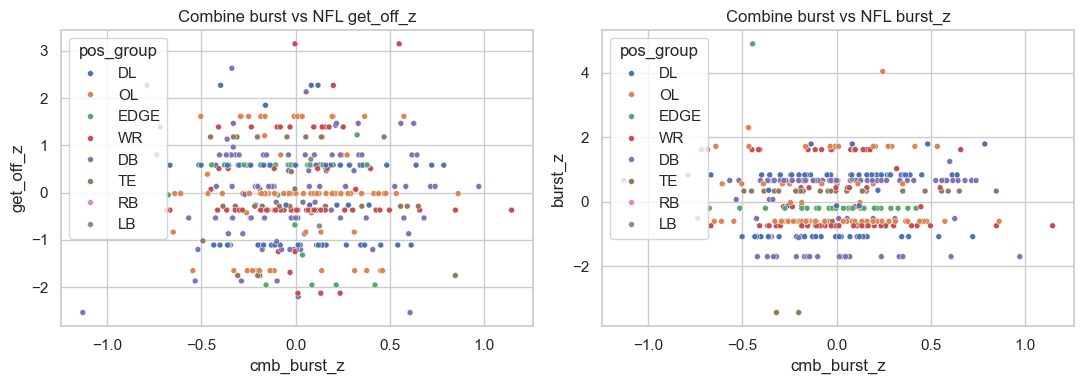

In [14]:
ct = pd.read_csv(find_csv("combine_tracking"), na_values=NULLS)
if "entity_type" in ct: ct = ct[ct["entity_type"] == "PLAYER"]
ct["time"] = pd.to_datetime(ct["time"], errors="coerce")
ct = ct.sort_values(["event_id", "nfl_id", "time"])
g = ct.groupby(["event_id", "nfl_id"])
ct["tt"] = (ct["time"] - g["time"].transform("first")).dt.total_seconds()
moving = ct["s"] > 0.5
first = ct[moving].groupby(["event_id", "nfl_id"]).head(1)[["event_id", "nfl_id", "tt", "x", "y"]].rename(columns={"tt": "t0", "x": "x0", "y": "y0"})
ct = ct.merge(first, on=["event_id", "nfl_id"])
ct["d0"] = np.hypot(ct["x"] - ct["x0"], ct["y"] - ct["y0"])
b = (ct[(ct["tt"] >= ct["t0"]) & (ct["d0"] >= 1.5)].groupby(["event_id", "nfl_id", "drill_name"])
       .apply(lambda d: d["tt"].iloc[0] - d["t0"].iloc[0]).rename("cmb_burst").reset_index())
b = b.merge(prof[["nfl_id", "pos_group"]], on="nfl_id")
b["z"] = b.groupby(["drill_name", "pos_group"])["cmb_burst"].transform(lambda s: (s - s.mean()) / s.std())
cmb = b.groupby("nfl_id").agg(cmb_burst_z=("z", "mean"), cmb_attempts=("z", "size"))
prof = prof.drop(columns=[c for c in cmb if c in prof]).merge(cmb, left_on="nfl_id", right_index=True, how="left")
if "ten_yd_split" in prof:
    prof["ten_yd_z"] = prof.groupby("pos_group")["ten_yd_split"].transform(lambda s: (s - s.mean()) / s.std())
CMB = [c for c in ["cmb_burst_z", "ten_yd_z"] if c in prof]
print("Combine burst available for", prof["cmb_burst_z"].notna().sum(), "players | lower z = quicker")

# (a) transfer: player-typical NFL get-off/burst (median over games) vs Combine
nfl_typ = panel[panel["played"]].groupby("nfl_id")[["get_off", "burst"]].median()
tr = prof.set_index("nfl_id")[CMB + ["pos_group"]].join(nfl_typ, how="inner")
for c in ["get_off", "burst"]: tr[f"{c}_z"] = tr.groupby("pos_group")[c].transform(lambda s: (s - s.mean()) / s.std())
rows = []
for grp_name, d in [("all", tr), ("OL", tr[tr["pos_group"] == "OL"])]:
    for x in CMB:
        for y in ["get_off_z", "burst_z"]:
            dd = d[[x, y]].dropna()
            if len(dd) < 10: continue
            r = stats.spearmanr(dd[x], dd[y])[0]
            bs = [stats.spearmanr(*dd.sample(len(dd), replace=True, random_state=i).T.values)[0] for i in range(500)]
            rows.append({"group": grp_name, "combine": x, "nfl": y, "rho": r, "lo": np.nanpercentile(bs, 2.5), "hi": np.nanpercentile(bs, 97.5), "n": len(dd)})
display(pd.DataFrame(rows).round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, y in zip(axes, ["get_off_z", "burst_z"]):
    sns.scatterplot(data=tr, x="cmb_burst_z", y=y, hue="pos_group", s=18, ax=ax); ax.set_title(f"Combine burst vs NFL {y}")
plt.tight_layout(); plt.show()

In [15]:
# (b) Moderation: does Combine burst change the cost of load spikes and injury listings?
mm = m.merge(prof[["nfl_id"] + CMB], on="nfl_id", how="left")
fit("next_dev_go_ms", ["spike*cmb_burst_z", "low_load", "cum_snaps_100"], mm, "M2×Combine: load spike × Combine burst")
fit("dev_go_ms", ["listed_lower*cmb_burst_z", "listed_other"], mm, "M3×Combine: lower-body listing × Combine burst")
print("Read: a negative interaction means players with LOWER (quicker) Combine burst z lose MORE; positive = quicker Combine burst players are protected.")


M2×Combine: load spike × Combine burst | MixedLM (random intercept, powell, reml=True) | n games=3,877, players=275


,coef_ms,ci_lo,ci_hi,p
Intercept,1.02,-7.34,9.38,0.81
C(pos_group)[T.DL],-6.82,-15.45,1.81,0.12
C(pos_group)[T.EDGE],-8.42,-19.34,2.51,0.13
C(pos_group)[T.OL],-8.13,-16.44,0.17,0.05
C(pos_group)[T.TE],-6.38,-20.50,7.75,0.38
C(pos_group)[T.WR],-7.22,-15.89,1.46,0.10
C(pos_group)[T.other],-91.86,-190.56,6.85,0.07
spike,4.20,-2.32,10.72,0.21
cmb_burst_z,-2.60,-13.07,7.88,0.63
spike:cmb_burst_z,-4.77,-24.99,15.45,0.64



M3×Combine: lower-body listing × Combine burst | MixedLM (random intercept, powell, reml=True) | n games=5,013, players=299


,coef_ms,ci_lo,ci_hi,p
Intercept,3.30,-2.07,8.68,0.23
C(pos_group)[T.DL],-6.48,-14.23,1.26,0.10
C(pos_group)[T.EDGE],-4.67,-14.96,5.62,0.37
C(pos_group)[T.OL],-3.71,-11.10,3.69,0.33
C(pos_group)[T.TE],-3.57,-15.29,8.15,0.55
C(pos_group)[T.WR],-6.23,-13.69,1.23,0.10
C(pos_group)[T.other],-39.75,-106.63,27.13,0.24
listed_lower,-3.93,-13.58,5.71,0.42
cmb_burst_z,0.12,-8.33,8.58,0.98
listed_lower:cmb_burst_z,-9.99,-39.41,19.44,0.51


Read: a negative interaction means players with LOWER (quicker) Combine burst z lose MORE; positive = quicker Combine burst players are protected.


Average season wear: -0.28 ms per game (positive = slower as the season goes on). Player spread (SD of slopes): 1.04
  cmb_burst_z vs wear slope: ρ=-0.03 (n=377, p=0.524)
  ten_yd_z vs wear slope: ρ=0.03 (n=318, p=0.554)


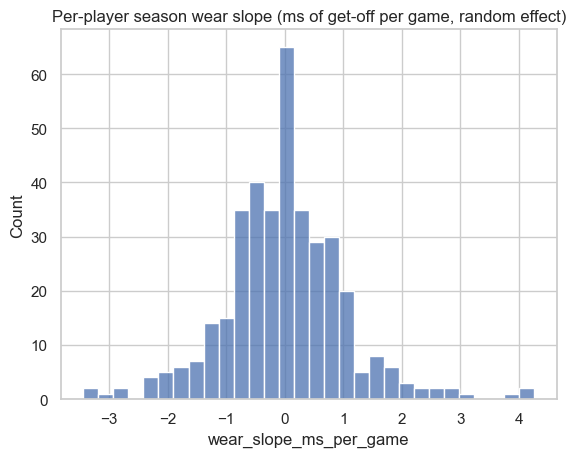

In [16]:
# (c) Season wear slopes (M1 random effects) vs Combine
if not hasattr(results["M1 season wear"], "random_effects"):
    print("M1 fell back to OLS — no per-player wear slopes available"); re = pd.DataFrame()
else:
    re = pd.DataFrame(results["M1 season wear"].random_effects).T
slope_col = [c for c in re.columns if "game_no" in c]
if slope_col:
    wear = re[slope_col[0]].rename("wear_slope_ms_per_game")
    w = prof.set_index("nfl_id")[CMB + ["pos_group", PICK] if PICK else CMB + ["pos_group"]].join(wear, how="inner")
    fixed = results["M1 season wear"].params.get("game_no_c", 0)
    print(f"Average season wear: {fixed:+.2f} ms per game (positive = slower as the season goes on). Player spread (SD of slopes): {wear.std():.2f}")
    for x in CMB:
        d = w[[x, "wear_slope_ms_per_game"]].dropna()
        if len(d) >= 10:
            r, p = stats.spearmanr(d[x], d["wear_slope_ms_per_game"])
            print(f"  {x} vs wear slope: ρ={r:.2f} (n={len(d)}, p={p:.3f})")
    sns.histplot(wear, bins=30); plt.title("Per-player season wear slope (ms of get-off per game, random effect)"); plt.show()

In [17]:
# (d) Injury onset rate by Combine burst tercile (real labels), with and without draft pick held constant
expo = panel[panel["played"]].groupby("nfl_id").agg(games=("game_id", "size"))
evn = panel.groupby("nfl_id").agg(onsets=("onset", "sum"), lower_onsets=("onset_region", lambda s: (s == "lower").sum()))
pr = prof.set_index("nfl_id")[CMB + ["pos_group"] + ([PICK] if PICK else [])].join(expo).join(evn).dropna(subset=["games"])
pr = pr[pr["games"] > 0]
for x in CMB:
    pr[f"{x}_t"] = pd.qcut(pr[x].rank(method="first"), 3, labels=["quick", "mid", "slow"])
    t = pr.groupby(f"{x}_t", observed=True)[["onsets", "lower_onsets", "games"]].sum()
    for e in ["onsets", "lower_onsets"]:
        t[[f"{e}_rate", f"{e}_lo", f"{e}_hi"]] = [poisson_rate(a, g) for a, g in zip(t[e], t["games"])]
    print(f"\n{x} tercile (per 100 games played):"); display(t.round(2))
if PICK:
    pr["log_pick"] = np.log(pr[PICK].fillna(pr[PICK].max() + 32))
    for x in CMB:
        d = pr[[x, "log_pick", "onsets", "games"]].dropna()
        if len(d) > 20:
            r = smf.poisson("onsets ~ " + x + " + log_pick", d, offset=np.log(d["games"])).fit(disp=0)
            print(f"Poisson onsets ~ {x} + log_pick: rate ratio per 1 SD = {np.exp(r.params[x]):.2f} "
                  f"[{np.exp(r.conf_int().loc[x, 0]):.2f}, {np.exp(r.conf_int().loc[x, 1]):.2f}]")


cmb_burst_z tercile (per 100 games played):


,onsets,lower_onsets,games,onsets_rate,onsets_lo,onsets_hi,lower_onsets_rate,lower_onsets_lo,lower_onsets_hi
cmb_burst_z_t,,,,,,,,,
quick,255.0,155.0,2808.0,9.08,8.00,10.27,5.52,4.69,6.46
mid,234.0,148.0,2555.0,9.16,8.02,10.41,5.79,4.90,6.80
slow,251.0,158.0,2527.0,9.93,8.74,11.24,6.25,5.32,7.31



ten_yd_z tercile (per 100 games played):


,onsets,lower_onsets,games,onsets_rate,onsets_lo,onsets_hi,lower_onsets_rate,lower_onsets_lo,lower_onsets_hi
ten_yd_z_t,,,,,,,,,
quick,222.0,150.0,2350.0,9.45,8.24,10.77,6.38,5.40,7.49
mid,202.0,116.0,2221.0,9.10,7.88,10.44,5.22,4.32,6.26
slow,200.0,124.0,2125.0,9.41,8.15,10.81,5.84,4.85,6.96


Poisson onsets ~ cmb_burst_z + log_pick: rate ratio per 1 SD = 1.10 [0.88, 1.38]
Poisson onsets ~ ten_yd_z + log_pick: rate ratio per 1 SD = 1.00 [0.92, 1.08]


## 8. Onset prediction with real labels (grouped CV)

**Outcome:** a new injury listing in the player's **next** team week, using only this game's tracking.

**Feature sets**, each adding to the last:
1. playing time (snap z, low-load flag, exit flag)
2. \+ movement (get-off z, burst z, hard-decel spike)
3. \+ Combine burst

Players are held out whole (5-fold grouped CV), and AUCs get player-clustered bootstrap CIs. This runs for all positions, for OL, and for lower-body onsets.

In [ ]:
d0 = panel[panel["played"] & panel["established"] & panel["z_get_off"].notna()].merge(prof[["nfl_id"] + CMB], on="nfl_id", how="left")
d0["exit_f"] = d0["exit"].astype(float)
SETS = {"1 playing time": ["z_trk_reps", "low_load", "exit_f"],
        "2 + movement": ["z_trk_reps", "low_load", "exit_f", "z_get_off", "z_burst", "spike"],
        "3 + Combine burst": ["z_trk_reps", "low_load", "exit_f", "z_get_off", "z_burst", "spike"] + CMB}
# Same games for every feature set (so AUCs are comparable); missing Combine values → 0 plus a missing flag
d0 = d0.dropna(subset=SETS["2 + movement"])
for c in CMB:
    d0[f"{c}_missing"] = d0[c].isna().astype(float); d0[c] = d0[c].fillna(0)
SETS["3 + Combine burst"] += [f"{c}_missing" for c in CMB]
out = []
for scope, sub in [("all", d0), ("OL", d0[d0["pos_group"] == "OL"])]:
    for tgt in ["next_onset", "next_onset_lower"]:
        for name, cols in SETS.items():
            dd = sub
            y = dd[tgt].astype(int).to_numpy()
            if y.sum() < 10 or dd["nfl_id"].nunique() < 10: continue
            X, grp, p = dd[cols].to_numpy(), dd["nfl_id"].to_numpy(), np.zeros(len(dd))
            for tr_, te_ in GroupKFold(5).split(X, y, grp):
                mdl = LogisticRegression(class_weight="balanced", max_iter=2000, C=0.5).fit(X[tr_], y[tr_])
                p[te_] = mdl.predict_proba(X[te_])[:, 1]
            a, lo, hi = cluster_boot_auc(y, p, grp)
            out.append({"scope": scope, "target": tgt, "features": name, "auc": a, "lo": lo, "hi": hi, "events": int(y.sum()), "games": len(y)})
pred = pd.DataFrame(out)
display(pred.round(3))

## 9. Synthesis

In [ ]:
def coef(name, term):
    r = results.get(name)
    if r is None or term not in r.params: return np.nan, np.nan, np.nan
    ci = r.conf_int().loc[term]; return r.params[term], ci[0], ci[1]
lines = []
for name, term, label in [("M1 season wear", "game_no_c", "season wear (ms per game)"),
                          ("M2 load → next-game get-off", "spike", "hard-decel spike → next-game get-off (ms)"),
                          ("M2 load → next-game get-off", "cum_snaps_100", "per 100 cumulative snaps (ms)"),
                          ("M3b lower-body vs other listings", "listed_lower", "playing with a lower-body listing (ms)"),
                          ("M3b lower-body vs other listings", "listed_other", "playing with another listing (ms)"),
                          ("M2×Combine: load spike × Combine burst", "spike:cmb_burst_z", "spike × Combine burst interaction"),
                          ("M3×Combine: lower-body listing × Combine burst", "listed_lower:cmb_burst_z", "lower-body listing × Combine burst")]:
    c, lo, hi = coef(name, term)
    lines.append({"finding": label, "estimate": c, "ci_lo": lo, "ci_hi": hi, "excludes_0": (lo > 0) or (hi < 0) if pd.notna(lo) else np.nan})
display(pd.DataFrame(lines).round(2))
if len(pred):
    display(pred.pivot_table(index=["scope", "target"], columns="features", values="auc").round(3))

panel.to_csv("cohort_getoff_panel.csv", index=False)
prof[["nfl_id", "pos_group"] + CMB].to_csv("cohort_combine_burst.csv", index=False)
print("Saved cohort_getoff_panel.csv and cohort_combine_burst.csv")

### What would make this a strong BDB story

- **§5a shows a lower-body listing slowing get-off by a clear margin, within player**, more than other listings. Then get-off behaves like a health readout.
- **§5b shows get-off slowing at lag −1** (the injury game) and staying slow after return, with §5c giving a recovery timeline. That's a "return to baseline" metric teams could use.
- **M2 shows load spikes slowing next-game get-off.** Then movement degrades *before* injuries are reported, which links the load literature to something visible on the field.
- **§7 shows Combine burst transferring into NFL get-off, or moderating the cost of load or injury.** Then the Combine has a role beyond "how fast is he." It predicts how well his movement holds up.
- **§8: if movement adds AUC over playing time with real labels and many more events,** that's the predictive payoff the OL-only analysis couldn't reach.

If the injury-status effects are real but the prediction AUCs stay near 0.5, the honest framing is that **get-off measures health, but it doesn't forecast injuries a week ahead.** That's still a useful and novel result.